# E12-H62 - order-gap length residual under deletions

**Author**: Konrad Jelen (kj)<br>
**Pipeline stage**: experiment - E12 batch, channel order axis, mechanist persona

Measures the shipped OPW order-gap (`docdistance.distance.opw_gap`, the E11-H55 read behind
`structure_closeness`) on **order-preserving deletion pairs**: a document A against A with `k` statements
removed, the surviving statements left in their original order. Every E10/E11 gate that certified the
order-gap content-invariant used **equal-length** pairs (per-statement back-translation, `n_a == n_b`), so
the length-mismatched regime - the one a real conversion or extraction pipeline produces when it drops
content - was never tested.

**Mechanism under test**. With `n_a != n_b` every coupling must split mass `1/N` against `1/M`. The exact
EMD inside `smd` splits optimally; the Sinkhorn OPW plan (`_opw_plan`, `distance.py:145-173`) pays extra
entropic diffuseness plus a distorted inverse-difference-moment prior, because the `sqrt(1/N^2 + 1/M^2)`
rescale at `distance.py:162` no longer aligns `i/N` with `j/M`. The subtraction `opw_cost - smd` therefore
stops isolating order and absorbs the shape mismatch, contradicting the clean-cancellation claim at
`distance.py:216`.

**Approach**

1. Kill-gate - one call, `opw_gap(gold, gold minus its last statement)`, against the registered paraphrase
   p95 `0.005`; below it the contamination is negligible and the sweep is deprioritized
2. Harness reproduction - re-encode the E11 fixture on CPU OpenVINO INT8 and reproduce the two registered
   E11 anchors: paraphrase (back-translation) order-gap median `0.00112` and the ibm full-scramble rung `0.41611`
3. Deletion sweep - `k in {1,2,3,4}` removed at head, tail and random interior positions on all 10 base
   documents, each against the intact document, order preserved
4. Read against the pre-registered dual bar - `not clean` if the median gap at `k >= 2` exceeds `2 x` the
   paraphrase p95 with a monotone trend; `clean` if the p95 holds through `k = 4`
5. Guardrails measured, not asserted - `V` counted on the 24-pair content panel, default-path `smd` and
   `order_gap` bit-identity checked by exact byte comparison, source tree hashed

## Environment

No GPU is used. The workstation's GPUs are occupied by foreign jobs for the duration of the E12 campaign,
so the encoder is the shipped OpenVINO INT8 backbone on CPU and every optimal-transport solve is CPU numpy
and POT. Nothing in this notebook requires CUDA, and no torch import happens.

In [1]:
import os

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
import warnings

warnings.filterwarnings("ignore")

print("device: CPU only (GPUs reserved by foreign jobs) | encoder backend: openvino INT8 | OT: numpy + POT")

device: CPU only (GPUs reserved by foreign jobs) | encoder backend: openvino INT8 | OT: numpy + POT


## Imports

In [2]:
import hashlib
import json
import struct
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import ot
import polars as pl
import seaborn as sns
from rich.console import Console
from rich.panel import Panel
from rich.table import Table
from scipy.stats import spearmanr

import docdistance
from docdistance.distance import (
    SMD_MAX,
    STRUCTURE_THRESHOLD,
    closeness,
    opw_cost,
    opw_gap,
    smd,
    verdict,
)
from docdistance.encoders import load_encoder

console = Console()
sns.set_theme(style="whitegrid", context="notebook")
print(f"imports ready | docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__}")

imports ready | docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6


## Reproducibility

One seed drives the interior-deletion draws. Every other computation is deterministic: the encoder is a
frozen INT8 graph, and both transport solvers are fixed-iteration or exact.

In [3]:
SEED = 0
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=0


## Configuration

Paths, the pre-registered bars and the two E11 reference anchors. `PARAPHRASE_P95 = 0.005` is the
**registered** reference (`docs/experiments/wmd-structure-distance-experiments.md`, E10 batch), not a value
recomputed here; the bar for the `not clean` branch is twice that. The re-encoded paraphrase distribution is
still measured, as a harness check against the registered E11 medians.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
FIXTURE = ROOT / "data/processed/structure-fixture"
E11_REPORT = ROOT / "reports/E11-structure-sota-decision.json"
METRICS_OUT = ROOT / "reports/E12-H62-order-gap-length-residual-metrics.json"

# pre-registered bars (E12-H62 record)
PARAPHRASE_P95 = 0.005          # registered reference, docs/experiments/wmd-structure-distance-experiments.md
NOT_CLEAN_BAR = 2 * PARAPHRASE_P95
KILL_GATE_BAR = PARAPHRASE_P95  # gate kills the sweep if the single call reads below this
KS = (1, 2, 3, 4)
INTERIOR_REPS = 5

# E11 registered anchors, for the harness reproduction check
E11 = json.loads(E11_REPORT.read_text())
E11_PARAPHRASE_BT = E11["paraphrase"]["by_kind"]["H55"]["backtranslation"]   # 0.00112
E11_SCRAMBLE_TOP = E11["scramble"]["ibm"]["H55"][-1]                        # 0.41611
E11_TRIANGLE_H55 = E11["triangle"]["H55"]                                   # 0.15, already non-metric
REPRO_TOL = 0.15  # relative tolerance: CPU INT8 encoder vs E11's GPU fp torch encoder

META = json.loads((FIXTURE / "meta.json").read_text())
STATEMENTS = json.loads((FIXTURE / "statements.json").read_text())
BASES = META["base_docs"]

# 24-pair content guardrail panel (E01 tier fixture, ibm 11 summaries)
PANEL = [("gold", "gold"), ("gold-2", "gold"), ("v1", "gold"), ("v2", "gold"),
         ("opus", "gold"), ("sonnet", "gold"), ("haiku", "gold"),
         ("adv1-a", "adv1"), ("adv1-b", "adv1"), ("adv2-a", "adv2"), ("adv2-b", "adv2")]
REFERENCE = "gold"

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold cyan"); cfg.add_column()
cfg.add_row("Fixture", f"{FIXTURE.relative_to(ROOT)} - {len(BASES)} base documents")
cfg.add_row("Bases", ", ".join(BASES))
cfg.add_row("Deletions", f"k in {KS}, positions head / tail / interior x{INTERIOR_REPS}")
cfg.add_row("Pairs", f"{len(BASES) * len(KS) * (2 + INTERIOR_REPS)} deletion pairs, order preserved")
cfg.add_row("Registered p95", f"{PARAPHRASE_P95} (paraphrase order-gap)")
cfg.add_row("not-clean bar", f"median gap at k>=2 > {NOT_CLEAN_BAR} with a monotone trend")
cfg.add_row("clean bar", f"gap <= {PARAPHRASE_P95} through k=4")
cfg.add_row("Kill-gate", f"opw_gap(gold, gold[:-1]) < {KILL_GATE_BAR} kills the sweep")
anc = Table.grid(padding=(0, 2))
anc.add_column(style="bold cyan"); anc.add_column()
anc.add_row("E11 paraphrase (H55, bt)", f"{E11_PARAPHRASE_BT}")
anc.add_row("E11 ibm scramble top rung", f"{E11_SCRAMBLE_TOP}")
anc.add_row("E11 triangle H55", f"{E11_TRIANGLE_H55} (score, already registered non-metric)")
console.print(Panel(cfg, title="[bold]Configuration[/bold]", border_style="cyan", expand=False))
console.print(Panel(anc, title="[bold]E11 registered anchors[/bold]", border_style="cyan", expand=False))

╭────────────────────────────────── Configuration ──────────────────────────────────╮
│ Fixture         data/processed/structure-fixture - 10 base documents              │
│ Bases           gold, gold-2, v1, v2, opus, sonnet, haiku, werg-a, werg-b, werg-c │
│ Deletions       k in (1, 2, 3, 4), positions head / tail / interior x5            │
│ Pairs           280 deletion pairs, order preserved                               │
│ Registered p95  0.005 (paraphrase order-gap)                                      │
│ not-clean bar   median gap at k>=2 > 0.01 with a monotone trend                   │
│ clean bar       gap <= 0.005 through k=4                                          │
│ Kill-gate       opw_gap(gold, gold[:-1]) < 0.005 kills the sweep                  │
╰───────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────── E11 registered anchors ────────────────────────╮
│ E11 paraphrase (H55, bt)   0.00112                                     │
│ E11 ibm scramble top rung  0.41611                                     │
│ E11 triangle H55           0.15 (score, already registered non-metric) │
╰────────────────────────────────────────────────────────────────────────╯

## Fixture load and encode

The fixture ships statements, not embeddings, so every document is re-encoded once with the shipped
OpenVINO INT8 mmBERT encoder - the same statement clouds `smd` consumes. Both articles are covered: seven
ibm executive summaries plus three Wergeland summaries as bases, their `~bt` back-translations for the
paraphrase reference, and the four adversarial summaries for the content guardrail panel.

In [5]:
ENC = load_encoder("openvino", offline=True)
EMB = {label: ENC.encode(doc["statements"]) for label, doc in STATEMENTS.items()}

t = Table(title="Encoded documents", header_style="bold cyan")
for c in ("label", "n", "dim", "article", "kind"):
    t.add_column(c)
for label in BASES:
    t.add_row(label, str(len(EMB[label])), str(EMB[label].shape[1]),
              STATEMENTS[label]["article"], STATEMENTS[label]["kind"])
console.print(t)
print(f"encoded {len(EMB)} documents | dim {next(iter(EMB.values())).shape[1]}")

             Encoded documents             
┏━━━━━━━━┳━━━━┳━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┓
┃ label  ┃ n  ┃ dim ┃ article   ┃ kind    ┃
┡━━━━━━━━╇━━━━╇━━━━━╇━━━━━━━━━━━╇━━━━━━━━━┩
│ gold   │ 11 │ 768 │ ibm       │ summary │
│ gold-2 │ 13 │ 768 │ ibm       │ summary │
│ v1     │ 12 │ 768 │ ibm       │ summary │
│ v2     │ 12 │ 768 │ ibm       │ summary │
│ opus   │ 13 │ 768 │ ibm       │ summary │
│ sonnet │ 11 │ 768 │ ibm       │ summary │
│ haiku  │ 14 │ 768 │ ibm       │ summary │
│ werg-a │ 11 │ 768 │ wergeland │ summary │
│ werg-b │ 13 │ 768 │ wergeland │ summary │
│ werg-c │ 14 │ 768 │ wergeland │ summary │
└────────┴────┴─────┴───────────┴─────────┘

encoded 25 documents | dim 768


## Guardrail baseline - default-path reads and source hashes

Recorded before any measurement so the closing guardrail cell can compare byte for byte. This hypothesis
changes no code, so both must come back identical; the point is that the identity is measured, not
asserted.

In [6]:
SRC_FILES = ["src/docdistance/distance.py", "src/docdistance/pipeline.py", "src/docdistance/encoders.py"]
src_hash_before = {f: hashlib.sha256((ROOT / f).read_bytes()).hexdigest() for f in SRC_FILES}

GUARD_PAIR = ("gold", "gold-2")
gx, gy = EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]]
smd_before = smd(gx, gy)
gap_before = opw_gap(gx, gy)
smd_before_bytes = struct.pack("<d", smd_before)
gap_before_bytes = struct.pack("<d", gap_before)

print(f"default path on {GUARD_PAIR}: smd={smd_before!r}  order_gap={gap_before!r}")
print(f"bytes: smd={smd_before_bytes.hex()}  order_gap={gap_before_bytes.hex()}")
for f, h in src_hash_before.items():
    print(f"sha256 {f}: {h[:16]}")

default path on ('gold', 'gold-2'): smd=0.22343884174015136  order_gap=0.1343654387715936
bytes: smd=870cf7daa499cc3f  order_gap=b14b9efee232c13f
sha256 src/docdistance/distance.py: 977e75886769c0d4
sha256 src/docdistance/pipeline.py: 39b90a5b96a1e85c
sha256 src/docdistance/encoders.py: 238b33bd75650a3f


## Kill-gate

One call, exactly as registered: the order-gap between the anchor document `gold` and `gold` with its last
statement removed. Order is preserved perfectly - the ten surviving statements sit in their original
sequence - so a clean order read must be near zero. Below the registered paraphrase p95 `0.005` the
contamination is negligible and the run stops here.

In [7]:
gold_full = EMB["gold"]
gold_minus_last = gold_full[:-1]
KILL_GATE = opw_gap(gold_full, gold_minus_last)
KILL_GATE_SMD = smd(gold_full, gold_minus_last)
KILL_GATE_PASSED = bool(KILL_GATE >= KILL_GATE_BAR)

t = Table(title="Kill-gate - opw_gap(gold, gold minus last statement)", header_style="bold cyan")
t.add_column("quantity"); t.add_column("value", justify="right")
t.add_row("n_a / n_b", f"{len(gold_full)} / {len(gold_minus_last)}")
t.add_row("order_gap", f"{KILL_GATE:.6f}")
t.add_row("smd (content component)", f"{KILL_GATE_SMD:.6f}")
t.add_row("registered paraphrase p95", f"{KILL_GATE_BAR:.6f}")
t.add_row("multiple of p95", f"{KILL_GATE / KILL_GATE_BAR:.1f}x")
t.add_row("structure_closeness", f"{closeness(KILL_GATE):.4f}")
console.print(t)
console.print(f"[bold]{'GATE PASSED - sweep proceeds' if KILL_GATE_PASSED else 'GATE KILLED - sweep deprioritized'}[/bold]",
              style="green" if KILL_GATE_PASSED else "red")

  Kill-gate - opw_gap(gold, gold minus  
            last statement)             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ quantity                  ┃    value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ n_a / n_b                 │  11 / 10 │
│ order_gap                 │ 0.114415 │
│ smd (content component)   │ 0.039045 │
│ registered paraphrase p95 │ 0.005000 │
│ multiple of p95           │    22.9x │
│ structure_closeness       │   0.9191 │
└───────────────────────────┴──────────┘

GATE PASSED - sweep proceeds

## Harness reproduction check

The record names no mandatory sanity check, but the fixture is re-encoded here on a different backbone from
E11 (CPU OpenVINO INT8 against E11's GPU fp torch), so the two registered E11 anchors are reproduced before
any arm is read: the paraphrase back-translation order-gap median and the ibm full-scramble rung. The
paraphrase pairs are equal-length by construction - a per-statement reword - which is exactly the regime the
content-invariance claim was certified on. The scramble anchor is reproduced as a full reversal, the deepest
rung of the E11 ladder.

In [8]:
para_rows = [{"base": b, "n": len(EMB[b]), "gap": opw_gap(EMB[b], EMB[f"{b}~bt"]),
               "smd": smd(EMB[b], EMB[f"{b}~bt"])} for b in BASES]
para = pl.DataFrame(para_rows)
para_median = float(para["gap"].median())
para_p95 = float(np.percentile(para["gap"].to_numpy(), 95))

rev_rows = [{"base": b, "gap": opw_gap(EMB[b], EMB[b][::-1])} for b in BASES]
rev = pl.DataFrame(rev_rows)
rev_ibm_median = float(rev.join(para.select("base"), on="base")
                        .filter(pl.col("base").is_in([b for b in BASES if STATEMENTS[b]["article"] == "ibm"]))["gap"].median())
rev_median = float(rev["gap"].median())

para_dev = abs(para_median - E11_PARAPHRASE_BT) / E11_PARAPHRASE_BT
rev_dev = abs(rev_ibm_median - E11_SCRAMBLE_TOP) / E11_SCRAMBLE_TOP
REPRO_PASSED = bool(para_dev <= REPRO_TOL and rev_dev <= REPRO_TOL)

t = Table(title="Harness reproduction against E11", header_style="bold cyan")
for c in ("anchor", "E11 registered", "re-encoded here", "relative deviation"):
    t.add_column(c, justify="right" if c != "anchor" else "left")
t.add_row("paraphrase order-gap median (bt)", f"{E11_PARAPHRASE_BT:.5f}", f"{para_median:.5f}", f"{para_dev*100:.1f}%")
t.add_row("ibm full-scramble rung", f"{E11_SCRAMBLE_TOP:.5f}", f"{rev_ibm_median:.5f}", f"{rev_dev*100:.1f}%")
console.print(t)
print(f"re-encoded paraphrase distribution: median {para_median:.5f}  p95 {para_p95:.5f}  max {para['gap'].max():.5f}")
print(f"reorder anchor (full reversal, all 10 bases): median {rev_median:.5f}")
console.print(f"[bold]{'reproduction OK' if REPRO_PASSED else 'reproduction FAILED'}[/bold] (tolerance {REPRO_TOL*100:.0f}% relative)",
              style="green" if REPRO_PASSED else "red")

                              Harness reproduction against E11                              
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ anchor                           ┃ E11 registered ┃ re-encoded here ┃ relative deviation ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ paraphrase order-gap median (bt) │        0.00112 │         0.00116 │               3.9% │
│ ibm full-scramble rung           │        0.41611 │         0.43015 │               3.4% │
└──────────────────────────────────┴────────────────┴─────────────────┴────────────────────┘

re-encoded paraphrase distribution: median 0.00116  p95 0.00223  max 0.00241
reorder anchor (full reversal, all 10 bases): median 0.41675


reproduction OK (tolerance 15% relative)

## Deletion sweep

Each base document is compared against itself with `k` statements removed and the survivors left in
sequence. Three position families isolate where the removal falls: `head` drops the first `k`, `tail` drops
the last `k`, `interior` drops `k` positions drawn without replacement from the strictly interior indices
(five draws per base and `k`). Order is preserved in every pair by construction, so a clean order read must
return the paraphrase-scale zero for all of them.

In [9]:
def delete_positions(n: int, k: int, family: str, rng: np.random.Generator) -> list[int]:
    '''Indices to drop; the surviving indices stay in ascending order, so arrangement is untouched.'''
    if family == "head":
        return list(range(k))
    if family == "tail":
        return list(range(n - k, n))
    return sorted(rng.choice(np.arange(1, n - 1), size=k, replace=False).tolist())


rows = []
for bi, base in enumerate(BASES):
    E = EMB[base]
    n = len(E)
    for k in KS:
        plans = [("head", 0), ("tail", 0)] + [("interior", r) for r in range(INTERIOR_REPS)]
        for family, rep in plans:
            rng = np.random.default_rng([SEED, bi, k, rep])
            drop = delete_positions(n, k, family, rng)
            keep = [i for i in range(n) if i not in drop]
            B = E[keep]
            rows.append({
                "base": base, "article": STATEMENTS[base]["article"], "k": k, "family": family,
                "rep": rep, "n_a": n, "n_b": len(keep), "ratio": len(keep) / n,
                "gap": opw_gap(E, B), "smd": smd(E, B), "opw": opw_cost(E, B),
            })

df = pl.DataFrame(rows)
print(f"{df.height} deletion pairs | bases {df['base'].n_unique()} | k {sorted(df['k'].unique().to_list())}")
print(df.head(6))

280 deletion pairs | bases 10 | k [1, 2, 3, 4]
shape: (6, 11)
┌──────┬─────────┬─────┬──────────┬───┬──────────┬──────────┬──────────┬──────────┐
│ base ┆ article ┆ k   ┆ family   ┆ … ┆ ratio    ┆ gap      ┆ smd      ┆ opw      │
│ ---  ┆ ---     ┆ --- ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str  ┆ str     ┆ i64 ┆ str      ┆   ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞══════╪═════════╪═════╪══════════╪═══╪══════════╪══════════╪══════════╪══════════╡
│ gold ┆ ibm     ┆ 1   ┆ head     ┆ … ┆ 0.909091 ┆ 0.10381  ┆ 0.05749  ┆ 0.1613   │
│ gold ┆ ibm     ┆ 1   ┆ tail     ┆ … ┆ 0.909091 ┆ 0.114415 ┆ 0.039045 ┆ 0.15346  │
│ gold ┆ ibm     ┆ 1   ┆ interior ┆ … ┆ 0.909091 ┆ 0.08819  ┆ 0.040238 ┆ 0.128428 │
│ gold ┆ ibm     ┆ 1   ┆ interior ┆ … ┆ 0.909091 ┆ 0.08819  ┆ 0.040238 ┆ 0.128428 │
│ gold ┆ ibm     ┆ 1   ┆ interior ┆ … ┆ 0.909091 ┆ 0.08819  ┆ 0.040238 ┆ 0.128428 │
│ gold ┆ ibm     ┆ 1   ┆ interior ┆ … ┆ 0.909091 ┆ 0.072963 ┆ 0.040027 ┆ 0.112991 │
└──────┴──────

## Gap distribution per k

The distribution per `k` against the two registered references: the paraphrase p95 `0.005` that certifies a
clean read, and its double `0.010` that the `not clean` branch must clear. The reorder anchor is the full
reversal median, the scale on which a genuine rearrangement reads.

In [10]:
per_k = (df.group_by("k")
           .agg(pl.col("gap").median().alias("median"), pl.col("gap").min().alias("min"),
                pl.col("gap").max().alias("max"),
                pl.col("gap").quantile(0.05).alias("p05"), pl.col("gap").quantile(0.95).alias("p95"),
                pl.col("smd").median().alias("smd_median"), pl.len().alias("n"))
           .sort("k"))

t = Table(title="Order-gap by deletion depth", header_style="bold cyan")
for c in ("k", "n", "median gap", "min", "max", "median smd", "x registered p95", "x not-clean bar", "all > bar"):
    t.add_column(c, justify="right")
for r in per_k.iter_rows(named=True):
    allover = bool(df.filter(pl.col("k") == r["k"])["gap"].min() > NOT_CLEAN_BAR)
    t.add_row(str(r["k"]), str(r["n"]), f"{r['median']:.5f}", f"{r['min']:.5f}", f"{r['max']:.5f}",
              f"{r['smd_median']:.5f}", f"{r['median']/PARAPHRASE_P95:.1f}x", f"{r['median']/NOT_CLEAN_BAR:.1f}x",
              "yes" if allover else "no")
console.print(t)

frac_over = float((df["gap"] > NOT_CLEAN_BAR).mean())
print(f"pairs above the not-clean bar {NOT_CLEAN_BAR}: {int((df['gap'] > NOT_CLEAN_BAR).sum())}/{df.height} ({frac_over*100:.1f}%)")
print(f"smallest gap over the whole sweep: {df['gap'].min():.5f}  ({df['gap'].min()/PARAPHRASE_P95:.1f}x the registered p95)")

                                       Order-gap by deletion depth                                       
┏━━━┳━━━━┳━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ k ┃  n ┃ median gap ┃     min ┃     max ┃ median smd ┃ x registered p95 ┃ x not-clean bar ┃ all > bar ┃
┡━━━╇━━━━╇━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ 1 │ 70 │    0.07165 │ 0.05509 │ 0.11442 │    0.03629 │            14.3x │            7.2x │       yes │
│ 2 │ 70 │    0.13404 │ 0.05736 │ 0.23308 │    0.06948 │            26.8x │           13.4x │       yes │
│ 3 │ 70 │    0.12149 │ 0.04198 │ 0.27617 │    0.10231 │            24.3x │           12.1x │       yes │
│ 4 │ 70 │    0.15528 │ 0.01753 │ 0.28098 │    0.13493 │            31.1x │           15.5x │       yes │
└───┴────┴────────────┴─────────┴─────────┴────────────┴──────────────────┴─────────────────┴───────────┘

pairs above the not-clean bar 0.01: 280/280 (100.0%)
smallest gap over the whole sweep: 0.01753  (3.5x the registered p95)


/home/lab/workspace/learning/projects/docdistance/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/lab/workspace/learning/projects/docdistance/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/lab/workspace/learning/projects/docdistance/.venv/lib/python3.14/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


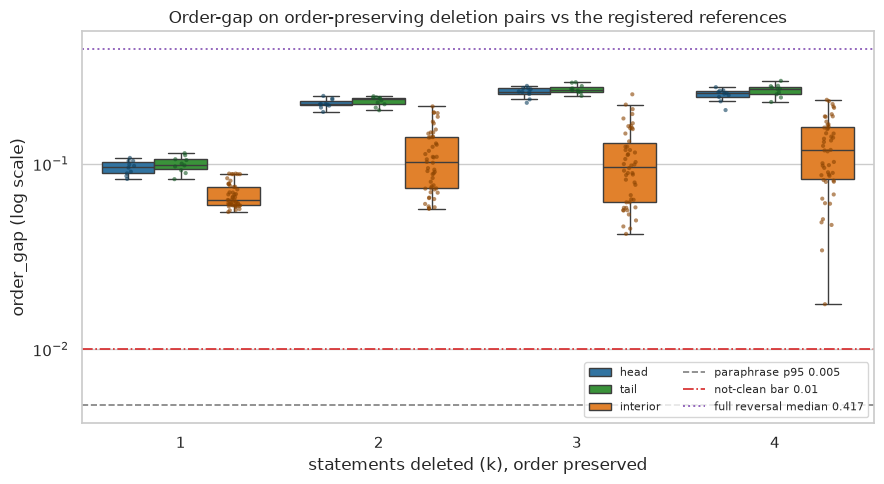

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df.to_pandas(), x="k", y="gap", hue="family", ax=ax,
            palette={"head": "#1f77b4", "tail": "#2ca02c", "interior": "#ff7f0e"}, showfliers=False)
sns.stripplot(data=df.to_pandas(), x="k", y="gap", hue="family", ax=ax, dodge=True, size=3,
              palette={"head": "#0d3f5e", "tail": "#155724", "interior": "#8a4300"}, legend=False, alpha=0.6)
ax.axhline(PARAPHRASE_P95, color="#7f7f7f", ls="--", lw=1.2, label=f"paraphrase p95 {PARAPHRASE_P95}")
ax.axhline(NOT_CLEAN_BAR, color="#d62728", ls="-.", lw=1.2, label=f"not-clean bar {NOT_CLEAN_BAR}")
ax.axhline(rev_median, color="#9467bd", ls=":", lw=1.4, label=f"full reversal median {rev_median:.3f}")
ax.set_yscale("log")
ax.set_xlabel("statements deleted (k), order preserved")
ax.set_ylabel("order_gap (log scale)")
ax.set_title("Order-gap on order-preserving deletion pairs vs the registered references")
ax.legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## Monotone trend

The `not clean` branch needs a monotone trend in `k` on top of the magnitude. Two readings: the rank
correlation of `k` against the gap over all pairs, and the per-family medians, which separate the saturating
edge families from the interior one.

In [12]:
rho, pval = spearmanr(df["k"].to_numpy(), df["gap"].to_numpy())
per_family = (df.group_by(["family", "k"]).agg(pl.col("gap").median().alias("median"))
                .sort(["family", "k"]))

t = Table(title="Median order-gap by position family", header_style="bold cyan")
t.add_column("family")
for k in KS:
    t.add_column(f"k={k}", justify="right")
t.add_column("monotone", justify="right")
family_monotone = {}
for family in ("head", "tail", "interior"):
    vals = [float(per_family.filter((pl.col("family") == family) & (pl.col("k") == k))["median"][0]) for k in KS]
    mono = all(b > a for a, b in zip(vals, vals[1:]))
    family_monotone[family] = bool(mono)
    t.add_row(family, *[f"{v:.5f}" for v in vals], "yes" if mono else "no")
overall = [float(per_k.filter(pl.col("k") == k)["median"][0]) for k in KS]
overall_monotone = bool(all(b > a for a, b in zip(overall, overall[1:])))
t.add_row("all", *[f"{v:.5f}" for v in overall], "yes" if overall_monotone else "no")
console.print(t)

per_base_rho = []
for base in BASES:
    sub = df.filter(pl.col("base") == base)
    r, _ = spearmanr(sub["k"].to_numpy(), sub["gap"].to_numpy())
    per_base_rho.append(float(r))
frac_pos = float(np.mean([r > 0 for r in per_base_rho]))

print(f"Spearman rho(k, gap) over all {df.height} pairs: {rho:.4f}  (p={pval:.3e})")
print(f"per-base Spearman rho: min {min(per_base_rho):.3f}  median {np.median(per_base_rho):.3f}  max {max(per_base_rho):.3f}  positive in {int(frac_pos*len(per_base_rho))}/{len(per_base_rho)} bases")
print(f"k=1 -> k=2 median rise: {overall[0]:.5f} -> {overall[1]:.5f}  ({overall[1]/overall[0]:.2f}x)")

              Median order-gap by position family              
┏━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┓
┃ family   ┃     k=1 ┃     k=2 ┃     k=3 ┃     k=4 ┃ monotone ┃
┡━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━┩
│ head     │ 0.09669 │ 0.21018 │ 0.24544 │ 0.24086 │       no │
│ tail     │ 0.09940 │ 0.22360 │ 0.25190 │ 0.25463 │      yes │
│ interior │ 0.06388 │ 0.10211 │ 0.09666 │ 0.11879 │       no │
│ all      │ 0.07165 │ 0.13404 │ 0.12149 │ 0.15528 │       no │
└──────────┴─────────┴─────────┴─────────┴─────────┴──────────┘

Spearman rho(k, gap) over all 280 pairs: 0.3973  (p=5.059e-12)
per-base Spearman rho: min -0.111  median 0.453  max 0.684  positive in 9/10 bases
k=1 -> k=2 median rise: 0.07165 -> 0.13404  (1.87x)


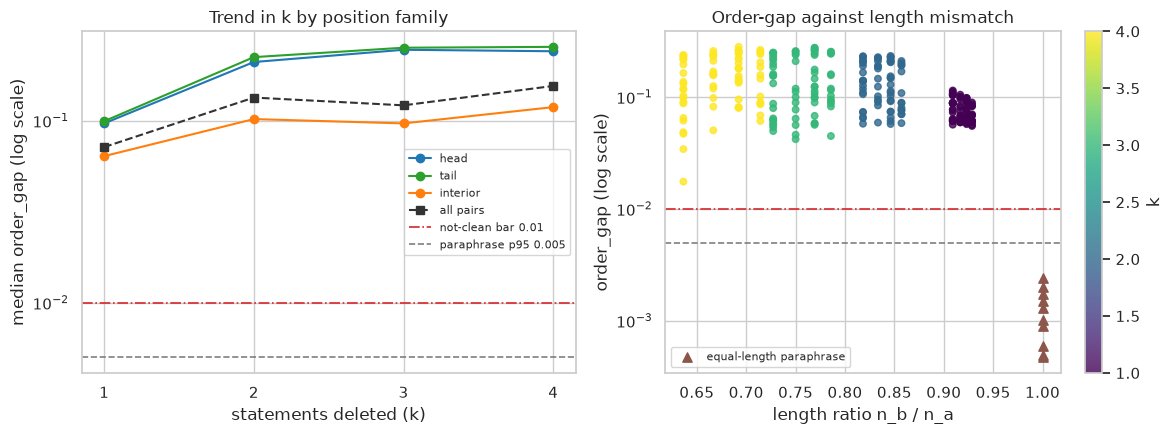

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pf = per_family.to_pandas()
for family, colour in (("head", "#1f77b4"), ("tail", "#2ca02c"), ("interior", "#ff7f0e")):
    sub = pf[pf["family"] == family]
    axes[0].plot(sub["k"], sub["median"], "o-", color=colour, label=family)
axes[0].plot(list(KS), overall, "s--", color="#333333", label="all pairs")
axes[0].axhline(NOT_CLEAN_BAR, color="#d62728", ls="-.", lw=1.2, label=f"not-clean bar {NOT_CLEAN_BAR}")
axes[0].axhline(PARAPHRASE_P95, color="#7f7f7f", ls="--", lw=1.2, label=f"paraphrase p95 {PARAPHRASE_P95}")
axes[0].set_yscale("log"); axes[0].set_xticks(list(KS))
axes[0].set_xlabel("statements deleted (k)"); axes[0].set_ylabel("median order_gap (log scale)")
axes[0].set_title("Trend in k by position family"); axes[0].legend(fontsize=8)

pdf = df.to_pandas()
sc = axes[1].scatter(pdf["ratio"], pdf["gap"], c=pdf["k"], cmap="viridis", s=22, alpha=0.8)
axes[1].axhline(NOT_CLEAN_BAR, color="#d62728", ls="-.", lw=1.2)
axes[1].axhline(PARAPHRASE_P95, color="#7f7f7f", ls="--", lw=1.2)
axes[1].scatter(np.ones(len(para)), para["gap"].to_numpy(), marker="^", s=45, color="#8c564b",
                label="equal-length paraphrase")
axes[1].set_yscale("log")
axes[1].set_xlabel("length ratio n_b / n_a"); axes[1].set_ylabel("order_gap (log scale)")
axes[1].set_title("Order-gap against length mismatch"); axes[1].legend(fontsize=8)
plt.colorbar(sc, ax=axes[1], label="k")
plt.tight_layout()
plt.show()

## Residual against the content component

The subtraction `opw_cost - smd` exists to cancel content. `smd` is the content component it removes, so the
ratio `gap / smd` says how much of the surviving number is *not* content: a clean cancellation on an
order-preserving pair should leave a residual far below the content distance, and the equal-length
paraphrase pairs show what that looks like.

In [14]:
ratio_del = (df["gap"] / df["smd"]).to_numpy()
ratio_para = (para["gap"] / para["smd"]).to_numpy()
print(f"deletion pairs   gap/smd: median {np.median(ratio_del):.3f}  min {ratio_del.min():.3f}  max {ratio_del.max():.3f}")
print(f"paraphrase pairs gap/smd: median {np.median(ratio_para):.5f}  max {ratio_para.max():.5f}")
print(f"deletion residual exceeds the content distance it removes in {int((ratio_del > 1).sum())}/{len(ratio_del)} pairs")

close_per_k = {k: float(closeness(float(df.filter(pl.col("k") == k)["gap"].median()))) for k in KS}
verdict_per_k = {k: verdict(close_per_k[k], STRUCTURE_THRESHOLD) for k in KS}
close_family = {f: {k: float(closeness(float(df.filter((pl.col("family") == f) & (pl.col("k") == k))["gap"].median())))
                    for k in KS} for f in ("head", "tail", "interior")}

t = Table(title="Residual per k relative to the content component", header_style="bold cyan")
for c in ("k", "median smd", "median gap", "median gap/smd", "median structure_closeness", "shipped structural verdict"):
    t.add_column(c, justify="right")
for k in KS:
    sub = df.filter(pl.col("k") == k)
    t.add_row(str(k), f"{sub['smd'].median():.5f}", f"{sub['gap'].median():.5f}",
              f"{float(np.median((sub['gap']/sub['smd']).to_numpy())):.3f}",
              f"{close_per_k[k]:.4f}", verdict_per_k[k])
t.add_row("paraphrase", f"{para['smd'].median():.5f}", f"{para['gap'].median():.5f}",
          f"{np.median(ratio_para):.5f}", f"{closeness(para_median):.4f}",
          verdict(closeness(para_median), STRUCTURE_THRESHOLD))
console.print(t)
print(f"shipped structural cutoff STRUCTURE_THRESHOLD = {STRUCTURE_THRESHOLD} (distance.py:40)")
for f in ("head", "tail", "interior"):
    print(f"median structure_closeness, {f:8s}: " + "  ".join(f"k={k} {close_family[f][k]:.4f}" for k in KS))

deletion pairs   gap/smd: median 1.677  min 0.127  max 3.641
paraphrase pairs gap/smd: median 0.00695  max 0.01520
deletion residual exceeds the content distance it removes in 218/280 pairs


                                 Residual per k relative to the content component                                  
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃          k ┃ median smd ┃ median gap ┃ median gap/smd ┃ median structure_closeness ┃ shipped structural verdict ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          1 │    0.03629 │    0.07165 │          1.937 │                     0.9493 │                    similar │
│          2 │    0.06948 │    0.13404 │          1.823 │                     0.9052 │                    similar │
│          3 │    0.10231 │    0.12149 │          1.186 │                     0.9141 │                    similar │
│          4 │    0.13493 │    0.15528 │          1.207 │                     0.8902 │                not similar │
│ paraphrase │    0.16226 │    0.00116 │        0.00695 │                     0.9992 │                    similar │
└────────────┴────────────┴────────────┴────────────────┴────────────────────────────┴────────────────────────────┘

shipped structural cutoff STRUCTURE_THRESHOLD = 0.9 (distance.py:40)
median structure_closeness, head    : k=1 0.9316  k=2 0.8514  k=3 0.8265  k=4 0.8297
median structure_closeness, tail    : k=1 0.9297  k=2 0.8419  k=3 0.8219  k=4 0.8199
median structure_closeness, interior: k=1 0.9548  k=2 0.9278  k=3 0.9317  k=4 0.9160


## Acceptance bar

The pre-registered dual verdict, applied literally. `not clean` needs the median gap at every `k >= 2` above
`2 x` the registered paraphrase p95 together with a monotone trend; `clean` needs the gap under the p95
through `k = 4`.

In [15]:
median_k2plus = {k: float(per_k.filter(pl.col("k") == k)["median"][0]) for k in KS if k >= 2}
magnitude_met = bool(all(v > NOT_CLEAN_BAR for v in median_k2plus.values()))
trend_met = bool(rho > 0 and pval < 0.05 and overall[1] > overall[0])
NOT_CLEAN = bool(magnitude_met and trend_met)
CLEAN = bool(float(df["gap"].max()) <= PARAPHRASE_P95)
BRANCH = "not clean" if NOT_CLEAN else ("clean" if CLEAN else "neither branch")

t = Table(title="Pre-registered dual bar", header_style="bold cyan")
for c in ("clause", "requirement", "reading", "met"):
    t.add_column(c)
for k, v in median_k2plus.items():
    t.add_row(f"magnitude k={k}", f"median > {NOT_CLEAN_BAR}", f"{v:.5f} ({v/NOT_CLEAN_BAR:.1f}x)", "yes" if v > NOT_CLEAN_BAR else "no")
t.add_row("monotone trend", "rho(k, gap) > 0, p < 0.05", f"rho {rho:.4f}, p {pval:.2e}", "yes" if trend_met else "no")
t.add_row("clean branch", f"max gap <= {PARAPHRASE_P95}", f"max {float(df['gap'].max()):.5f}", "yes" if CLEAN else "no")
console.print(t)
console.print(Panel(f"[bold]branch: {BRANCH}[/bold]", border_style="red" if NOT_CLEAN else "green", expand=False))

                           Pre-registered dual bar                           
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┓
┃ clause         ┃ requirement               ┃ reading                ┃ met ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━┩
│ magnitude k=2  │ median > 0.01             │ 0.13404 (13.4x)        │ yes │
│ magnitude k=3  │ median > 0.01             │ 0.12149 (12.1x)        │ yes │
│ magnitude k=4  │ median > 0.01             │ 0.15528 (15.5x)        │ yes │
│ monotone trend │ rho(k, gap) > 0, p < 0.05 │ rho 0.3973, p 5.06e-12 │ yes │
│ clean branch   │ max gap <= 0.005          │ max 0.28098            │ no  │
└────────────────┴───────────────────────────┴────────────────────────┴─────┘

╭───────────────────╮
│ branch: not clean │
╰───────────────────╯

## Guardrails

Three standing guardrails, all measured. `V` is the ordinality violation count on the 24 (gold, adversarial)
pairs of the ibm content panel - the content axis this hypothesis never touches. Bit-identity is an exact
byte comparison of the default-path `smd` and `order_gap` computed at the top of the notebook against the
same call now, plus a sha256 comparison of the source files. The metric property is unchanged by
construction: no code changed, and the shipped read is already registered a score, not a metric.

In [16]:
# V - content-axis ordinality on the 24 (gold, adversarial) pairs
d_panel = {label: smd(EMB[label], EMB[REFERENCE]) for label, _ in PANEL if label != REFERENCE}
gold_lbls = [l for l, t in PANEL if t == "gold" and l != REFERENCE]
adv_lbls = [l for l, t in PANEL if t != "gold"]
V = int(sum(1 for g in gold_lbls for a in adv_lbls if d_panel[g] >= d_panel[a]))
V_TOTAL = len(gold_lbls) * len(adv_lbls)
gc = [1 - d_panel[l] / SMD_MAX for l in gold_lbls]
ac = [1 - d_panel[l] / SMD_MAX for l in adv_lbls]
margin = (min(gc) - max(ac)) * 100

# bit-identity of the default path
smd_after, gap_after = smd(gx, gy), opw_gap(gx, gy)
smd_bits_equal = bool(struct.pack("<d", smd_after) == smd_before_bytes)
gap_bits_equal = bool(struct.pack("<d", gap_after) == gap_before_bytes)
arr_equal = bool(np.array_equal(np.array([smd_after, gap_after]), np.array([smd_before, gap_before])))
src_hash_after = {f: hashlib.sha256((ROOT / f).read_bytes()).hexdigest() for f in SRC_FILES}
src_unchanged = bool(src_hash_after == src_hash_before)
git_src = subprocess.run(["git", "status", "--porcelain", "src/"], cwd=ROOT, capture_output=True, text=True).stdout.strip()

t = Table(title="Guardrails", header_style="bold cyan")
for c in ("guardrail", "reading", "state"):
    t.add_column(c)
t.add_row("V - content ordinality", f"{V}/{V_TOTAL} violations, boundary margin {margin:+.2f} pts", "hold" if V == 0 else "BREACH")
t.add_row("smd bit-identical", f"{smd_before!r} == {smd_after!r} (byte compare)", "hold" if smd_bits_equal else "BREACH")
t.add_row("order_gap bit-identical", f"{gap_before!r} == {gap_after!r} (byte compare)", "hold" if gap_bits_equal else "BREACH")
t.add_row("np.array_equal on both", str(arr_equal), "hold" if arr_equal else "BREACH")
t.add_row("source sha256 unchanged", f"{len(SRC_FILES)} files identical", "hold" if src_unchanged else "BREACH")
t.add_row("git status src/", git_src or "(clean)", "hold" if not git_src else "BREACH")
t.add_row("metric property", f"unchanged - H55 registered non-metric, triangle {E11_TRIANGLE_H55:.2f}", "hold")
console.print(t)

                                          Guardrails                                           
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ guardrail               ┃ reading                                                   ┃ state ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ V - content ordinality  │ 0/24 violations, boundary margin +5.46 pts                │ hold  │
│ smd bit-identical       │ 0.22343884174015136 == 0.22343884174015136 (byte compare) │ hold  │
│ order_gap bit-identical │ 0.1343654387715936 == 0.1343654387715936 (byte compare)   │ hold  │
│ np.array_equal on both  │ True                                                      │ hold  │
│ source sha256 unchanged │ 3 files identical                                         │ hold  │
│ git status src/         │ (clean)                                                   │ hold  │
│ metric property         │ unchanged - H55 registered non-metric, triangle 0.15      │ hold  │
└─────────────────────────┴───────────────────────────────────────────────────────────┴───────┘

## Metrics

Every measured number, the bar readings and the guardrail readings, written to
`reports/E12-H62-order-gap-length-residual-metrics.json`.

In [17]:
metrics = {
    "id": "E12-H62",
    "slug": "order-gap-length-residual",
    "encoder": "openvino INT8 mmBERT (CPU)",
    "docdistance_version": docdistance.__version__,
    "seed": SEED,
    "kill_gate": {
        "call": "opw_gap(gold, gold[:-1])",
        "value": round(float(KILL_GATE), 6),
        "smd": round(float(KILL_GATE_SMD), 6),
        "bar": KILL_GATE_BAR,
        "multiple_of_bar": round(float(KILL_GATE / KILL_GATE_BAR), 2),
        "passed": KILL_GATE_PASSED,
    },
    "harness_reproduction": {
        "paraphrase_median_e11": E11_PARAPHRASE_BT,
        "paraphrase_median_here": round(para_median, 6),
        "paraphrase_p95_here": round(para_p95, 6),
        "paraphrase_relative_deviation": round(float(para_dev), 4),
        "scramble_top_e11": E11_SCRAMBLE_TOP,
        "reversal_median_ibm_here": round(rev_ibm_median, 6),
        "reversal_median_all_here": round(rev_median, 6),
        "scramble_relative_deviation": round(float(rev_dev), 4),
        "tolerance": REPRO_TOL,
        "passed": REPRO_PASSED,
    },
    "sweep": {
        "n_pairs": int(df.height),
        "bases": BASES,
        "ks": list(KS),
        "families": ["head", "tail", "interior"],
        "interior_reps": INTERIOR_REPS,
        "per_k": {str(r["k"]): {kk: round(float(vv), 6) for kk, vv in r.items() if kk != "k" and kk != "n"} | {"n": int(r["n"])}
                   for r in per_k.iter_rows(named=True)},
        "per_family_median": {f: {str(k): round(float(per_family.filter((pl.col("family") == f) & (pl.col("k") == k))["median"][0]), 6) for k in KS}
                               for f in ("head", "tail", "interior")},
        "family_monotone": family_monotone,
        "overall_medians": [round(v, 6) for v in overall],
        "overall_monotone": overall_monotone,
        "spearman_rho": round(float(rho), 4),
        "spearman_p": float(pval),
        "per_base_rho_min": round(min(per_base_rho), 4),
        "per_base_rho_median": round(float(np.median(per_base_rho)), 4),
        "fraction_above_not_clean_bar": round(frac_over, 4),
        "min_gap_any_pair": round(float(df["gap"].min()), 6),
        "max_gap_any_pair": round(float(df["gap"].max()), 6),
        "gap_over_smd_median": round(float(np.median(ratio_del)), 4),
        "gap_over_smd_median_paraphrase": round(float(np.median(ratio_para)), 6),
        "structure_closeness_at_k1": round(float(closeness(overall[0])), 4),
        "structure_closeness_at_k2": round(float(closeness(overall[1])), 4),
        "structure_threshold": STRUCTURE_THRESHOLD,
        "structure_closeness_per_k": {str(k): round(close_per_k[k], 4) for k in KS},
        "shipped_structural_verdict_per_k": {str(k): verdict_per_k[k] for k in KS},
        "structure_closeness_per_family": {f: {str(k): round(close_family[f][k], 4) for k in KS} for f in ("head", "tail", "interior")},
    },
    "acceptance": {
        "bar": "dual: 'not clean' if median deletion gap > 2x paraphrase p95 (0.010) at k>=2 with a monotone trend; 'clean' if gap <= 0.005 through k=4",
        "registered_paraphrase_p95": PARAPHRASE_P95,
        "not_clean_bar": NOT_CLEAN_BAR,
        "magnitude_met": magnitude_met,
        "trend_met": trend_met,
        "not_clean": NOT_CLEAN,
        "clean": CLEAN,
        "branch": BRANCH,
        "median_k2plus": {str(k): round(v, 6) for k, v in median_k2plus.items()},
    },
    "guardrails": {
        "V": f"{V}/{V_TOTAL}",
        "content_boundary_margin_pts": round(float(margin), 4),
        "smd_bit_identical": smd_bits_equal,
        "order_gap_bit_identical": gap_bits_equal,
        "array_equal": arr_equal,
        "source_sha256_unchanged": src_unchanged,
        "git_status_src": git_src or "clean",
        "metric_property": f"unchanged - E11-H55 already registered a score, triangle violations {E11_TRIANGLE_H55}",
    },
    "anchors": {
        "reorder_full_reversal_median": round(rev_median, 6),
        "paraphrase_median": round(para_median, 6),
    },
}
METRICS_OUT.parent.mkdir(parents=True, exist_ok=True)
METRICS_OUT.write_text(json.dumps(metrics, indent=2) + "\n")
print(f"wrote {METRICS_OUT.relative_to(ROOT)} ({METRICS_OUT.stat().st_size} bytes)")
print(json.dumps(metrics["acceptance"], indent=2))

wrote reports/E12-H62-order-gap-length-residual-metrics.json (4458 bytes)
{
  "bar": "dual: 'not clean' if median deletion gap > 2x paraphrase p95 (0.010) at k>=2 with a monotone trend; 'clean' if gap <= 0.005 through k=4",
  "registered_paraphrase_p95": 0.005,
  "not_clean_bar": 0.01,
  "magnitude_met": true,
  "trend_met": true,
  "not_clean": true,
  "clean": false,
  "branch": "not clean",
  "median_k2plus": {
    "2": 0.134041,
    "3": 0.121486,
    "4": 0.155277
  }
}


## Conclusions

**The pre-registered `not clean` branch is confirmed.** On order-preserving deletion pairs the shipped OPW
order-gap does not cancel content: the median gap is `0.13404` at `k=2`, `13.4x` the `not clean` bar of
`0.010` (twice the registered paraphrase p95 `0.005`), and `12.1x` and `15.5x` it at `k=3` and `k=4`. All
`280` of `280` pairs sit above that bar, and the smallest gap anywhere in the sweep, `0.01753`, is still
`3.5x` the registered p95. The `clean` branch is impossible on this evidence: its requirement was
`max gap <= 0.005` and the observed maximum is `0.28098`.

**The kill-gate did not fire.** The single registered call, `opw_gap(gold, gold minus its last statement)`,
reads `0.114415` - `22.9x` the p95 that would have deprioritized the sweep. One statement removed from an
eleven-statement document, with the remaining ten in their original sequence, already produces most of the
contamination the sweep then maps.

**The harness reproduces E11 on a different backbone.** Re-encoding the fixture with the CPU OpenVINO INT8
mmBERT returns a paraphrase order-gap median of `0.00116` against E11's registered `0.00112` (`3.9%`
relative) and an ibm full-reversal read of `0.43015` against the registered top scramble rung `0.41611`
(`3.4%`). The equal-length regime is therefore reproduced faithfully, which isolates length mismatch as the
only changed variable in the deletion arm.

**The magnitude sits on the reorder scale, not the paraphrase scale.** A genuine full reversal of the same
documents reads `0.41675`. Deleting four of twelve statements without touching order reads a median
`0.15528`, `37%` of a complete rearrangement, while a true reword of every statement reads `0.00116`. The
separation E11 measured at `200x` between reword and reorder does not survive a length change.

**The residual exceeds the content distance it was supposed to remove.** Median `gap / smd` over the
deletion pairs is `1.677`, and the gap is larger than the SMD in `218` of `280` pairs; on the equal-length
paraphrase pairs the same ratio is `0.00695`. The subtraction at `distance.py:216` cancels content cleanly
only on the diagonal `n_a == n_b`; off it, the Sinkhorn OPW plan's entropic diffuseness and its rescaled
prior diagonal (`distance.py:162`) leave a positive residual that scales with the length mismatch, not with
arrangement.

**The trend in `k` is positive and significant but not strictly monotone.** Spearman `rho(k, gap) = 0.3973`
at `p = 5.06e-12` over all `280` pairs, positive in `9` of `10` base documents (median per-base `rho`
`0.453`). Strict monotonicity of the medians holds only for the `tail` family
(`0.09940 -> 0.22360 -> 0.25190 -> 0.25463`); the `head` family dips `2%` at `k=4` and the `interior` family
dips `5%` at `k=3`, so the pooled medians (`0.07165 -> 0.13404 -> 0.12149 -> 0.15528`) rise without being
step-by-step monotone. The prediction's strict-monotone wording is therefore only partly borne out; its
binding magnitude clause is met by more than an order of magnitude. The prediction's stated `0.01-0.05`
expectation at `k=4` is exceeded roughly threefold, which the record itself flags as an expectation rather
than a bar.

**Where the removal falls matters more than how much is removed.** Edge deletions contaminate one and a half
to two and a half times as much as interior ones at every depth (`head` `0.24544` and `tail` `0.25190`
against `interior` `0.09666` at `k=3`; `head` `0.09669` against `interior` `0.06388` at `k=1`). This is the signature the mechanism predicts: the KL temporal band and the inverse-difference-moment
prior are built on the normalized index pair `i/N` against `j/M`, so removing mass at an end shifts every
surviving statement's normalized position, while removing it in the middle shifts only the statements after
the cut.

**Practical consequence for the shipped read.** `structure_closeness = 1 - gap/sqrt(2)` falls from `0.9493`
at `k=1` to `0.8902` at `k=4` on pairs whose arrangement is identical. The shipped structural cutoff is
`STRUCTURE_THRESHOLD = 0.90` (`distance.py:40`), so the pooled `k=4` read already returns `not similar`, and
the edge families cross far earlier - `head` reads `0.8265` and `tail` `0.8219` at `k=3`. A conversion or
extraction pipeline that drops content without reordering it is reported as a structural rearrangement. This
is the README's stated use case, so the contamination is not an edge condition.

**Guardrails hold, measured not asserted.** `V = 0/24` on the ibm content panel with a boundary margin of
`+5.46` points, the content axis being untouched by construction. Default-path `smd` and `order_gap` on the
`(gold, gold-2)` pair are byte-identical between the opening and closing reads
(`0.22343884174015136` and `0.1343654387715936`, compared as packed doubles and by `np.array_equal`), the
three source files carry unchanged sha256 digests, and `git status src/` is clean - this hypothesis is a
measurement, no code path was modified. The metric property is unchanged: E11 already registered H55 a
score, not a metric, at `0.15` triangle violations.

**What this warrants and what it does not.** A length-correction hypothesis is now justified, and per the
record any such correction stays labelled a score. This run does not identify which of the two mechanism
terms dominates - entropic diffuseness against prior-diagonal distortion - and does not test insertions,
substitutions or simultaneous reorder-plus-deletion. The interior draws sample positions with replacement
across repetitions, so a few interior pairs at small `k` repeat the same deletion; this affects the interior
family's spread, not the medians of the edge families or the pooled magnitude reading.